# 04 — Models and evaluation

Methods planned in the report (§1): **persistence** and **seasonal-mean** baselines, **Ridge regression**, **Random Forest** and
**gradient boosting** (scikit-learn `HistGradientBoostingRegressor`). They are compared with **chronological cross-validation**
and a **Diebold–Mariano test against persistence**. Secondary output: the **US EPA AQI category** of the forecast.

**Protocol (main station, US Embassy 7441)**

* Rows: issue days t where PM2.5 of t and t+1 are both valid (1,918 pairs). All models are scored on the same rows.
* **Development period**: Nov 2016 – Oct 2023. Models are compared there with 5 expanding-window folds in calendar time
  (first 2 years for training only; 1-day gap between train and test).
* **Hold-out test**: 1 Nov 2023 – 9 Apr 2025. It includes the two most recent winters and is used once, at the end.
* Hyper-parameters are fixed a priori (moderate, regularised settings). Ridge chooses α by internal CV on each training set.
  Nothing is tuned on the test period.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from plotting import apply_style, save, SERIES, TEXT_2, MODEL_COLORS, SEQ_CMAP
apply_style()
pd.set_option("display.width", 200, "display.max_columns", 40, "display.max_colwidth", 60)
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.metrics import confusion_matrix
from evaluation import make_models, cross_validate, expanding_folds, metrics, diebold_mariano, aqi_index
from preprocessing import AQI_LABELS

def load(loc):
    f = pd.read_csv(ROOT / f"data/processed/station_{loc}_features.csv", index_col=0, parse_dates=True)
    f = f[f[["target", "pm25_lag0"]].notna().all(axis=1)]
    return f.drop(columns=["target", "target_date"]), f["target"]

X, y = load(7441)
TEST_START = "2023-11-01"
dev, test = X.index < TEST_START, X.index >= TEST_START
print(f"features: {X.shape[1]} | development rows: {dev.sum()} | test rows: {test.sum()}")
models = make_models()

features: 35 | development rows: 1508 | test rows: 410


## 1. Chronological cross-validation on the development period

In [2]:
folds = list(expanding_folds(X.index[dev], n_folds=5, min_train_days=730))
for k, (tr, te) in enumerate(folds):
    print(f"fold {k}: train {X.index[dev][tr][0].date()} -> {X.index[dev][tr][-1].date()} ({len(tr)} rows) | "
          f"test {X.index[dev][te][0].date()} -> {X.index[dev][te][-1].date()} ({len(te)} rows)")
cv, oof = cross_validate(models, X[dev], y[dev], folds)
cv_summary = cv.groupby("model")[["MAE", "RMSE", "R2", "AQI_acc"]].agg(["mean", "std"]).round(2)
cv_summary.sort_values(("MAE", "mean"))

fold 0: train 2016-11-10 -> 2018-11-08 (464 rows) | test 2018-11-10 -> 2019-11-04 (192 rows)
fold 1: train 2016-11-10 -> 2019-11-04 (657 rows) | test 2019-11-09 -> 2020-11-05 (305 rows)
fold 2: train 2016-11-10 -> 2020-11-04 (961 rows) | test 2020-11-06 -> 2021-11-04 (185 rows)
fold 3: train 2016-11-10 -> 2021-11-03 (1146 rows) | test 2021-11-05 -> 2022-11-02 (105 rows)
fold 4: train 2016-11-10 -> 2022-11-01 (1251 rows) | test 2022-11-03 -> 2023-10-31 (256 rows)


MAE         RMSE          R2       AQI_acc      
                    mean   std   mean   std  mean   std    mean   std
model                                                                
Random Forest      11.87  1.70  16.48  2.38  0.64  0.12    0.65  0.05
Gradient Boosting  12.05  1.70  16.71  2.19  0.63  0.12    0.65  0.07
Ridge              12.21  1.96  16.58  2.66  0.64  0.13    0.65  0.05
Persistence        13.63  1.97  19.85  2.91  0.48  0.16    0.63  0.05
Seasonal mean      19.59  4.28  26.13  4.81  0.09  0.42    0.48  0.12

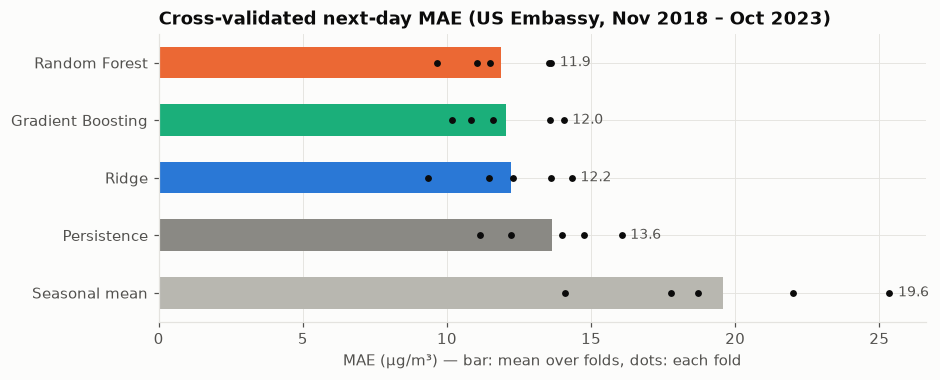

In [3]:
order = cv.groupby("model")["MAE"].mean().sort_values().index
fig, ax = plt.subplots(figsize=(9, 3.4))
for i, m in enumerate(order):
    vals = cv.loc[cv.model == m, "MAE"]
    ax.barh(i, vals.mean(), color=MODEL_COLORS[m], height=0.55)
    ax.scatter(vals, [i] * len(vals), color="#0b0b0b", s=12, zorder=3)
    ax.text(vals.max() + 0.3, i, f"{vals.mean():.1f}", va="center", color=TEXT_2, fontsize=9)
ax.set_yticks(range(len(order)), order); ax.invert_yaxis()
ax.set_xlabel("MAE (µg/m³) — bar: mean over folds, dots: each fold")
ax.set_title("Cross-validated next-day MAE (US Embassy, Nov 2018 – Oct 2023)")
save(fig, "04_cv_mae", ROOT)

In [4]:
# Diebold-Mariano on the pooled out-of-fold predictions (absolute-error loss), each model vs persistence
mask = oof.notna().all(axis=1)
dm_cv = pd.DataFrame({m: diebold_mariano(y[dev][mask], oof.loc[mask, m], oof.loc[mask, "Persistence"])
                      for m in oof if m != "Persistence"}).T
dm_cv.round(4)

,DM,p_value,mean_loss_diff,n
Seasonal mean,9.0420,0.0000,5.6460,1043.0
Ridge,-4.0034,0.0001,-1.4023,1043.0
Random Forest,-4.6349,0.0000,-1.7654,1043.0
Gradient Boosting,-3.9333,0.0001,-1.6019,1043.0


### Feature-set ablation (cross-validation)

What does each group of features add? We compare PM2.5 history only, history + calendar, and history + calendar + weather.

In [5]:
pm_cols = [c for c in X if c.startswith("pm25_")]
cal_cols = ["month", "dow", "is_weekend", "doy_sin", "doy_cos", "tet_period", "is_dry_season"]
sets = {"PM2.5 history": pm_cols, "+ calendar": pm_cols + cal_cols, "+ calendar + weather": list(X.columns)}
abl = []
for sname, cols in sets.items():
    for m in ["Ridge", "Random Forest", "Gradient Boosting"]:
        r, _ = cross_validate({m: models[m]}, X.loc[dev, cols], y[dev], folds)
        abl.append({"features": sname, "model": m, "MAE": r.MAE.mean(), "RMSE": r.RMSE.mean(), "R2": r.R2.mean()})
abl = pd.DataFrame(abl)
abl.pivot(index="model", columns="features", values="MAE")[list(sets)].round(2)

features,PM2.5 history,+ calendar,+ calendar + weather
model,,,
Gradient Boosting,15.14,14.49,12.05
Random Forest,13.89,13.72,11.87
Ridge,13.43,13.74,12.21


## 2. Hold-out test (Nov 2023 – Apr 2025)

In [6]:
fitted, pred = {}, {}
for name, m in models.items():
    fitted[name] = clone(m).fit(X[dev], y[dev])
    pred[name] = pd.Series(fitted[name].predict(X[test]), index=X.index[test])
pred = pd.DataFrame(pred)
res = pd.DataFrame({m: metrics(y[test], pred[m]) for m in pred}).T
res["skill_vs_persistence_MAE"] = 1 - res["MAE"] / res.loc["Persistence", "MAE"]
dm_test = pd.DataFrame({m: diebold_mariano(y[test], pred[m], pred["Persistence"]) for m in pred if m != "Persistence"}).T
res = res.join(dm_test[["DM", "p_value"]])
res.sort_values("MAE").round(3)

,MAE,RMSE,R2,AQI_acc,skill_vs_persistence_MAE,DM,p_value
Random Forest,10.197,14.503,0.634,0.683,0.180,-4.742,0.000
Gradient Boosting,10.250,14.700,0.624,0.671,0.176,-4.190,0.000
Ridge,11.001,14.861,0.616,0.641,0.115,-3.065,0.002
Persistence,12.435,17.231,0.483,0.600,0.000,NaN,NaN
Seasonal mean,16.665,22.204,0.142,0.507,-0.340,5.527,0.000


In [7]:
best = res.drop(["Persistence", "Seasonal mean"]).MAE.idxmin()
others = [m for m in ["Ridge", "Random Forest", "Gradient Boosting"] if m != best]
pd.DataFrame({f"{best} vs {o}": diebold_mariano(y[test], pred[best], pred[o]) for o in others}).T.round(4)

,DM,p_value,mean_loss_diff,n
Random Forest vs Ridge,-3.0260,0.0026,-0.8039,410.0
Random Forest vs Gradient Boosting,-0.2674,0.7893,-0.0531,410.0


In [8]:
season = np.where(X.index[test].month.isin([11, 12, 1, 2, 3]), "winter (Nov-Mar)", "rest of year")
by_season = pd.DataFrame({m: (pred[m] - y[test]).abs().groupby(season).mean() for m in pred}).T
by_season["n_winter"] = (season == "winter (Nov-Mar)").sum()
by_season.round(2)

,rest of year,winter (Nov-Mar),n_winter
Persistence,9.48,14.68,233
Seasonal mean,10.24,21.55,233
Ridge,8.43,12.95,233
Random Forest,7.70,12.10,233
Gradient Boosting,7.69,12.20,233


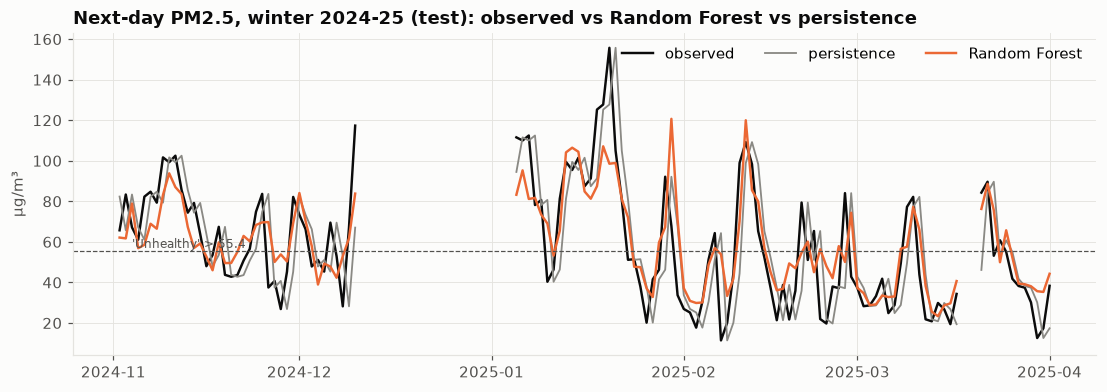

In [9]:
win = slice("2024-11-01", "2025-03-31")
yt = y[test].copy(); yt.index = yt.index + pd.Timedelta(days=1)      # plot against the target day
pt = pred.copy(); pt.index = pt.index + pd.Timedelta(days=1)
full = pd.date_range("2024-11-02", "2025-04-01")
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(full, yt.reindex(full)[full], color="#0b0b0b", lw=1.6, label="observed")
ax.plot(full, pt["Persistence"].reindex(full), color=MODEL_COLORS["Persistence"], lw=1.2, label="persistence")
ax.plot(full, pt[best].reindex(full), color=MODEL_COLORS[best], lw=1.6, label=best)
ax.axhline(55.4, color=TEXT_2, lw=0.8, ls="--"); ax.text(full[2], 57, "'Unhealthy' > 55.4", color=TEXT_2, fontsize=8)
ax.set_ylabel("µg/m³"); ax.legend(loc="upper right", ncol=3)
ax.set_title(f"Next-day PM2.5, winter 2024-25 (test): observed vs {best} vs persistence")
save(fig, "04_test_winter_2024_25", ROOT)

### What drives the best model? (permutation importance on the test period)

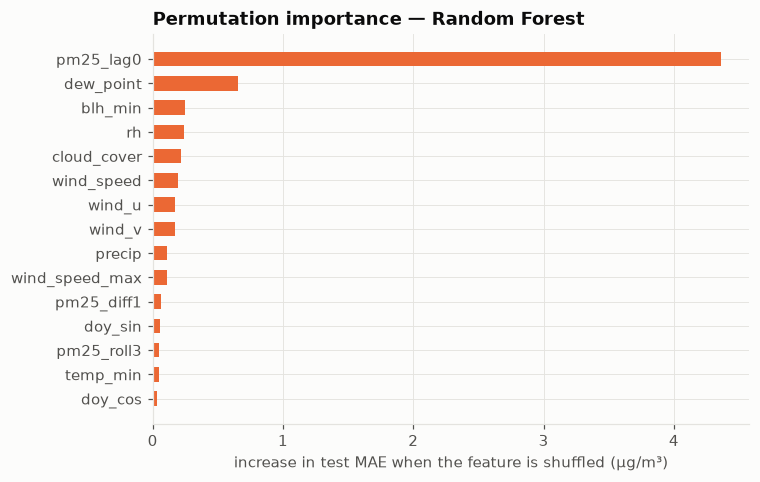

In [10]:
Xt = X[test].copy()
imp = permutation_importance(fitted[best], Xt, y[test], scoring="neg_mean_absolute_error", n_repeats=10, random_state=0)
imp = pd.Series(imp.importances_mean, index=X.columns).sort_values(ascending=False).head(15)
fig, ax = plt.subplots(figsize=(7, 4.6))
ax.barh(imp.index[::-1], imp.values[::-1], color=MODEL_COLORS[best], height=0.6)
ax.set_xlabel("increase in test MAE when the feature is shuffled (µg/m³)")
ax.set_title(f"Permutation importance — {best}")
save(fig, "04_permutation_importance", ROOT)

### Secondary output: AQI category

In [11]:
labels = list(range(len(AQI_LABELS)))
cm = pd.DataFrame(confusion_matrix(aqi_index(y[test]), aqi_index(pred[best]), labels=labels),
                  index=[f"true: {l}" for l in AQI_LABELS], columns=[f"pred: {l}" for l in AQI_LABELS])
cm = cm.loc[cm.sum(axis=1) > 0, cm.sum(axis=0) > 0]
print(f"{best}: AQI category accuracy {res.loc[best, 'AQI_acc']:.1%} vs persistence {res.loc['Persistence', 'AQI_acc']:.1%}")
cm

Random Forest: AQI category accuracy 68.3% vs persistence 60.0%


,pred: Moderate,pred: Unhealthy for sensitive groups,pred: Unhealthy
true: Moderate,106,41,6
true: Unhealthy for sensitive groups,33,94,29
true: Unhealthy,1,17,80
true: Very unhealthy,0,0,3


In [12]:
# 'Unhealthy or worse' (> 55.4) as an alert: hit rate and false alarms
def alert_scores(obs, prd, thr=55.4):
    o, p = obs > thr, prd > thr
    return {"events": int(o.sum()), "hit_rate": (o & p).sum() / o.sum(), "false_alarm_ratio": (p & ~o).sum() / max(p.sum(), 1)}
pd.DataFrame({m: alert_scores(y[test], pred[m]) for m in pred}).T.round(3)

,events,hit_rate,false_alarm_ratio
Persistence,101.0,0.663,0.343
Seasonal mean,101.0,0.337,0.590
Ridge,101.0,0.822,0.362
Random Forest,101.0,0.822,0.297
Gradient Boosting,101.0,0.782,0.288


## 3. Replication on the second station (Chi cục BVMT 2161292, the Kaggle source)

This series runs from Jan 2024 to Nov 2026 and has fewer valid days (589 pairs), so we use expanding-window
cross-validation only: 4 folds after a first year of training, no separate hold-out. The goal is to check whether the model
ranking holds on a different, currently active station.

In [13]:
X2, y2 = load(2161292)
folds2 = list(expanding_folds(X2.index, n_folds=4, min_train_days=365))
for k, (tr, te) in enumerate(folds2):
    print(f"fold {k}: train {len(tr)} rows -> test {X2.index[te][0].date()} to {X2.index[te][-1].date()} ({len(te)} rows)")
cv2, oof2 = cross_validate(make_models(), X2, y2, folds2)
m2 = oof2.notna().all(axis=1)
summary2 = pd.DataFrame({m: metrics(y2[m2], oof2.loc[m2, m]) for m in oof2}).T
summary2 = summary2.join(pd.DataFrame({m: diebold_mariano(y2[m2], oof2.loc[m2, m], oof2.loc[m2, "Persistence"])
                                       for m in oof2 if m != "Persistence"}).T[["DM", "p_value"]])
summary2.sort_values("MAE").round(3)

fold 0: train 296 rows -> test 2025-01-29 to 2025-06-14 (125 rows)
fold 1: train 422 rows -> test 2025-06-19 to 2025-10-31 (121 rows)
fold 2: train 542 rows -> test 2025-11-01 to 2026-03-12 (32 rows)
fold 3: train 575 rows -> test 2026-03-19 to 2026-08-03 (14 rows)


,MAE,RMSE,R2,AQI_acc,DM,p_value
Ridge,7.943,10.522,0.444,0.750,-0.619,0.536
Random Forest,8.190,10.723,0.422,0.781,-0.004,0.997
Persistence,8.192,11.285,0.360,0.767,NaN,NaN
Gradient Boosting,8.790,11.631,0.320,0.774,1.290,0.198
Seasonal mean,13.959,18.611,-0.740,0.603,8.104,0.000


In [14]:
out = ROOT / "reports"
cv.to_csv(out / "cv_folds_7441.csv", index=False)
res.to_csv(out / "test_results_7441.csv")
summary2.to_csv(out / "cv_results_2161292.csv")
abl.to_csv(out / "ablation_7441.csv", index=False)
pred.assign(observed=y[test]).to_csv(out / "test_predictions_7441.csv")

## Conclusions

**Main station — US Embassy (7441)**

| Model | CV MAE (5 folds, 2018–23) | Test MAE (Nov 2023 – Apr 2025) | Test RMSE | Test R² | Skill vs persistence | DM vs persistence (test) | AQI accuracy |
|---|---|---|---|---|---|---|---|
| Random Forest | **11.9** | **10.2** | **14.5** | **0.63** | **18 %** | −4.74, p < 0.001 | **68 %** |
| Gradient Boosting | 12.0 | 10.3 | 14.7 | 0.62 | 18 % | −4.19, p < 0.001 | 67 % |
| Ridge | 12.2 | 11.0 | 14.9 | 0.62 | 12 % | −3.07, p = 0.002 | 64 % |
| Persistence | 13.6 | 12.4 | 17.2 | 0.48 | — | — | 60 % |
| Seasonal mean | 19.6 | 16.7 | 22.2 | 0.14 | −34 % | +5.53 (worse) | 51 % |

1. **All three learned models beat persistence significantly**, in cross-validation and on the hold-out test (Diebold–Mariano,
   absolute-error loss, p ≤ 0.002). The seasonal mean alone is much worse than persistence: day-to-day persistence is the
   dominant signal.
2. **The two tree ensembles are tied** (RF vs GB on the test: DM = −0.27, p = 0.79). Both beat Ridge significantly (RF vs Ridge
   p = 0.003), which suggests non-linear effects, for example between the boundary-layer height and the season.
3. **Weather is what makes the difference.** With PM2.5 history only, the models barely improve on persistence (best: Ridge
   13.4 vs 13.6 µg/m³), and calendar features add almost nothing. Adding the same-day weather lowers the CV MAE by
   1.2–3.1 µg/m³. The most important variables after today's PM2.5 are dew point / humidity,
   the minimum boundary-layer height, cloud cover and wind.
4. **Winter is where errors are largest** (test MAE ≈ 12 µg/m³ in Nov–Mar vs ≈ 7.7 in the rest of the year), but it is also
   where the models gain most over persistence (14.7 → 12.1). For the alert "tomorrow Unhealthy (> 55.4 µg/m³)", the Random
   Forest detects 82 % of events (persistence: 66 %) with fewer false alarms (30 % vs 34 %).
5. Like every model of this kind, the forecasts lag sharp onsets of episodes by about a day (see the winter 2024-25 plot):
   the inputs describe today, not tomorrow's weather.

**Second station — Chi cục BVMT (2161292, the Kaggle source).** The data is short (≈ 290 out-of-fold days, a single well-covered
winter), and **no model beats persistence significantly** (Ridge MAE 7.9 vs 8.2, p = 0.54). Ridge comes first and gradient
boosting last, as expected when the training set is small. This confirms the choice of the long US Embassy series for model
comparison. A 2-year series like the Kaggle file is not enough to show a gain over persistence.

**Limits and next steps**

* The US Embassy monitor stopped in April 2025, so an operational forecaster would have to be re-trained on an active station
  (e.g. 2161292 or 4946812). Levels differ between stations by about 25 %, so the model cannot be transferred directly.
* Use **next-day weather forecasts** (Open-Meteo forecast / ERA5 of day t+1 as a proxy) as inputs, the main missing driver
  behind the lagged response to episode onsets.
* Tune hyper-parameters with nested chronological CV (here they are fixed a priori), and add PM2.5 from neighbouring stations
  and the CAMS forecast (Zenodo file) as features.